# 02 — Resultados, figuras e auditoria dos seis experimentos

Este notebook contém todos os elementos obrigatórios de resultados e os painéis de dados
usados no artigo. Ele **não treina nem executa inferência nos modelos**. Recalcula métricas
a partir das previsões já salvas e verifica sua igualdade com os relatórios publicados.
Execute-o apenas após o bloqueio de seleção e a avaliação final descritos no README.

O teste fica fora de ajustes de modelo e escolha de configuração. Abrir ou executar este
notebook não dispara nova avaliação de teste. Os valores exibidos vêm de artefatos reais;
não há números ilustrativos usados como resultados.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage

# Funciona ao iniciar Jupyter na raiz do projeto ou dentro de notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/experiments.json').is_file()
             and (p / 'src/prepare.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abra este notebook dentro da pasta trashnet do projeto.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluate import CLASSES, EXPERIMENTS, load_manifest, sha256_file
from src import visualize as vis

FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
vis.style()
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
manifest = load_manifest(ROOT)
eda = json.loads((ROOT / 'data/eda.json').read_text(encoding='utf-8'))
assert sha256_file(ROOT / 'data/manifest.csv') == eda['manifest_sha256']
assert CLASSES == eda['class_order']
print('Projeto:', ROOT.name)
print('Manifesto SHA-256:', eda['manifest_sha256'])

Projeto: trashnet
Manifesto SHA-256: 988a0a94bf617b8f3ab88e9d6da355001cb8fe2dc59f98004779bc245b9adf7f


## Dados e prevenção de vazamento

In [2]:
EXPECTED = pd.Series([501, 594, 403, 482, 410, 137], index=CLASSES, name='total')
counts = pd.crosstab(manifest.class_name, manifest.split).reindex(
    index=CLASSES, columns=['train', 'val', 'test'], fill_value=0)
counts['total'] = counts.sum(axis=1)
np.testing.assert_array_equal(counts['total'].to_numpy(), EXPECTED.to_numpy())
assert len(manifest) == 2527 and manifest.path.is_unique
assert manifest['split'].isin(['train', 'val', 'test']).all()
assert not eda['invalid_images']

for hash_column in ['sha256', 'pixel_sha256']:
    assert manifest.groupby(hash_column)['split'].nunique().max() == 1, (
        f'Vazamento de duplicata exata detectado: {hash_column}')

before = pd.read_csv(ROOT / 'data/manifest_before_grouping.csv')
before_counts = pd.crosstab(before.class_name, before.split).reindex(
    index=CLASSES, columns=['train', 'val', 'test'], fill_value=0)
pd.testing.assert_frame_equal(counts[['train', 'val', 'test']], before_counts)
assert set(before.path) == set(manifest.path)
pd.testing.assert_series_equal(before.set_index('path').label.sort_index(),
                               manifest.set_index('path').label.sort_index())
display(counts.rename(columns={'train':'treino', 'val':'validação', 'test':'teste'}))
split_sizes = manifest['split'].value_counts().reindex(['train', 'val', 'test'])
display(pd.DataFrame({'imagens': split_sizes, 'percentual': 100 * split_sizes / len(manifest)}))
display(pd.DataFrame({'valor': {'dimensões': eda['dimensions'], 'modos': eda['modes'],
                              'pré-processamento': eda['preprocessing'],
                              'aumento de dados': eda['augmentation']}}))
print('Contagens preservadas e hashes exatos restritos a uma única partição.')

split,treino,validação,teste,total
class_name,,,,
glass,350,75,76,501
paper,416,89,89,594
cardboard,282,61,60,403
plastic,337,72,73,482
metal,287,61,62,410
trash,96,21,20,137


,imagens,percentual
split,,
train,1768,69.964385
val,379,14.998021
test,380,15.037594


,valor
dimensões,{'512x384': 2527}
modos,{'RGB': 2527}
pré-processamento,EXIF transpose; RGB; Pillow LANCZOS a partir d...
aumento de dados,nenhum


Contagens preservadas e hashes exatos restritos a uma única partição.


## Duplicatas conflitantes: tratamento e limite

A divisão inicial usa duas chamadas estratificadas (70/30 e 50/50 do restante), ambas com
semente 42. A auditoria identifica grupos de imagens idênticas pelos hashes dos bytes e
dos pixels RGB. Um grupo não pode atravessar partições. Quando necessário, o membro é
movido para a partição da primeira linha estável do grupo e um singleton da mesma classe
faz a troca inversa. Isso preserva todos os suportes por classe e os 2.527 arquivos.

Os rótulos de origem são preservados: a correção elimina o vazamento exato, mas não elimina
ruído de anotação. Examine abaixo em quais partições os grupos ficaram. Não se verificou
independência completa por objeto, pois hashes não identificam necessariamente ângulos
diferentes de uma mesma peça. As tabelas seguintes são calculadas dos arquivos reais.

In [3]:
duplicates = manifest.loc[manifest.duplicated('pixel_sha256', keep=False)].sort_values(
    ['pixel_sha256', 'path'])
display(duplicates[['path', 'class_name', 'split', 'pixel_sha256']])
group_summary = duplicates.groupby('pixel_sha256').agg(
    arquivos=('path', 'size'), classes=('class_name', 'nunique'),
    partições=('split', 'nunique'), partição=('split', 'first'))
assert (group_summary['partições'] == 1).all()
assert len(group_summary) == eda['exact_duplicate_pixel_groups']
display(group_summary)
display(pd.DataFrame(eda['duplicate_repairs']))
print('Grupos exatos:', len(group_summary))
print('Grupos com rótulos conflitantes:', int((group_summary.classes > 1).sum()))
print('Partições dos grupos:', group_summary['partição'].value_counts().to_dict())
print(eda['near_duplicate_audit'])

,path,class_name,split,pixel_sha256
85,glass/glass176.jpg,glass,train,6939447168c001a71438496448c2b85513a3d5f1eb8b96...
1557,plastic/plastic152.jpg,plastic,train,6939447168c001a71438496448c2b85513a3d5f1eb8b96...
18,glass/glass115.jpg,glass,train,b2d08f52065ced309ba5ce64b66a8eeb65848808d08504...
2381,metal/metal91.jpg,metal,train,b2d08f52065ced309ba5ce64b66a8eeb65848808d08504...
321,glass/glass389.jpg,glass,train,c751e2644345c8376f0a511aa4e34341a779d473899d50...
1757,plastic/plastic332.jpg,plastic,train,c751e2644345c8376f0a511aa4e34341a779d473899d50...


,arquivos,classes,partições,partição
pixel_sha256,,,,
6939447168c001a71438496448c2b85513a3d5f1eb8b960fe7a7a8bf6452ab6c,2,2,1,train
b2d08f52065ced309ba5ce64b66a8eeb65848808d08504b0227665725c4e4b87,2,2,1,train
c751e2644345c8376f0a511aa4e34341a779d473899d506d05280304a3c210bc,2,2,1,train


,duplicate,singleton,original_split,grouped_split
0,plastic/plastic332.jpg,plastic/plastic1.jpg,val,train


Grupos exatos: 3
Grupos com rótulos conflitantes: 3
Partições dos grupos: {'train': 3}
Não há identificadores de objeto. Hashes evitam vazamento de duplicatas exatas; semelhança perceptual e múltiplas fotos do mesmo objeto não são totalmente controladas.


## Distribuição, exemplos e resolução

As figuras são reconstruídas pelas mesmas funções utilizadas no artigo. Os exemplos usam
apenas treino, com regra estável por caminho; não foram escolhidos segundo acertos do teste.
A ordem das classes é a do enunciado. Os painéis de resolução mostram a mesma imagem
nas três entradas, em largura × altura.

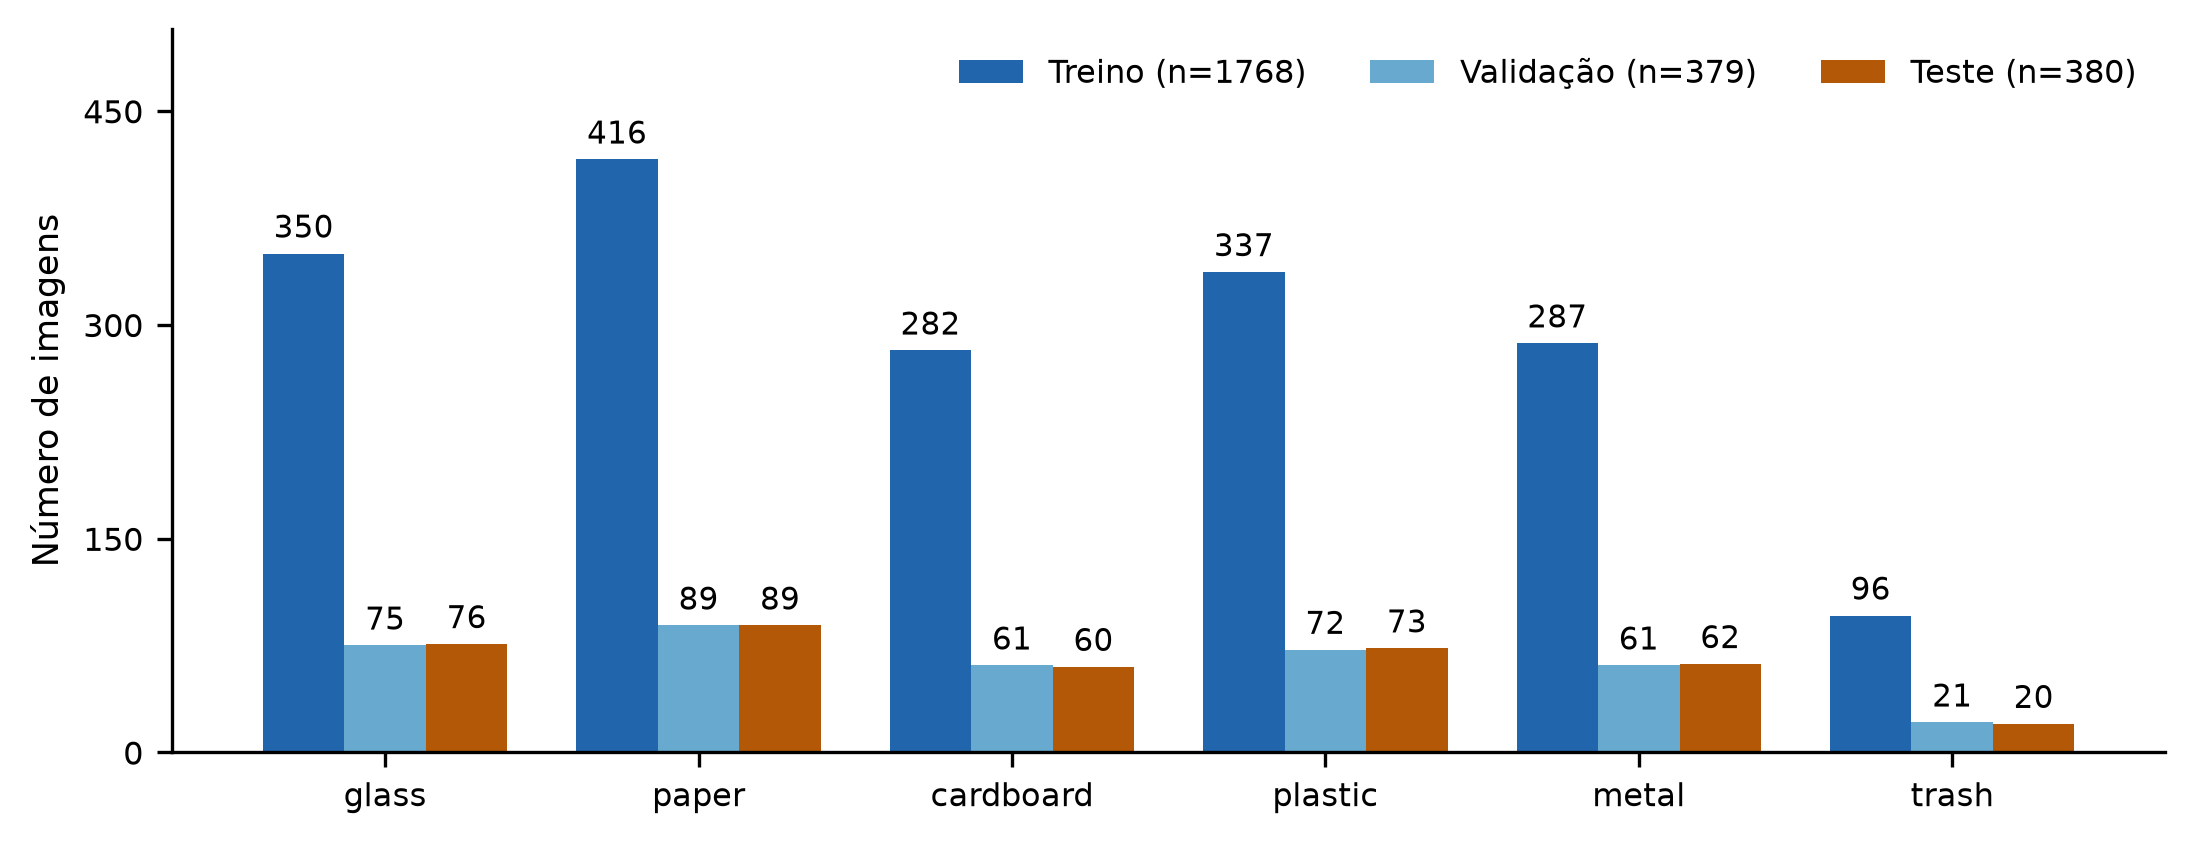

In [4]:
vis.distribution(ROOT, manifest, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig01_distribuicao.png'), width=1100))

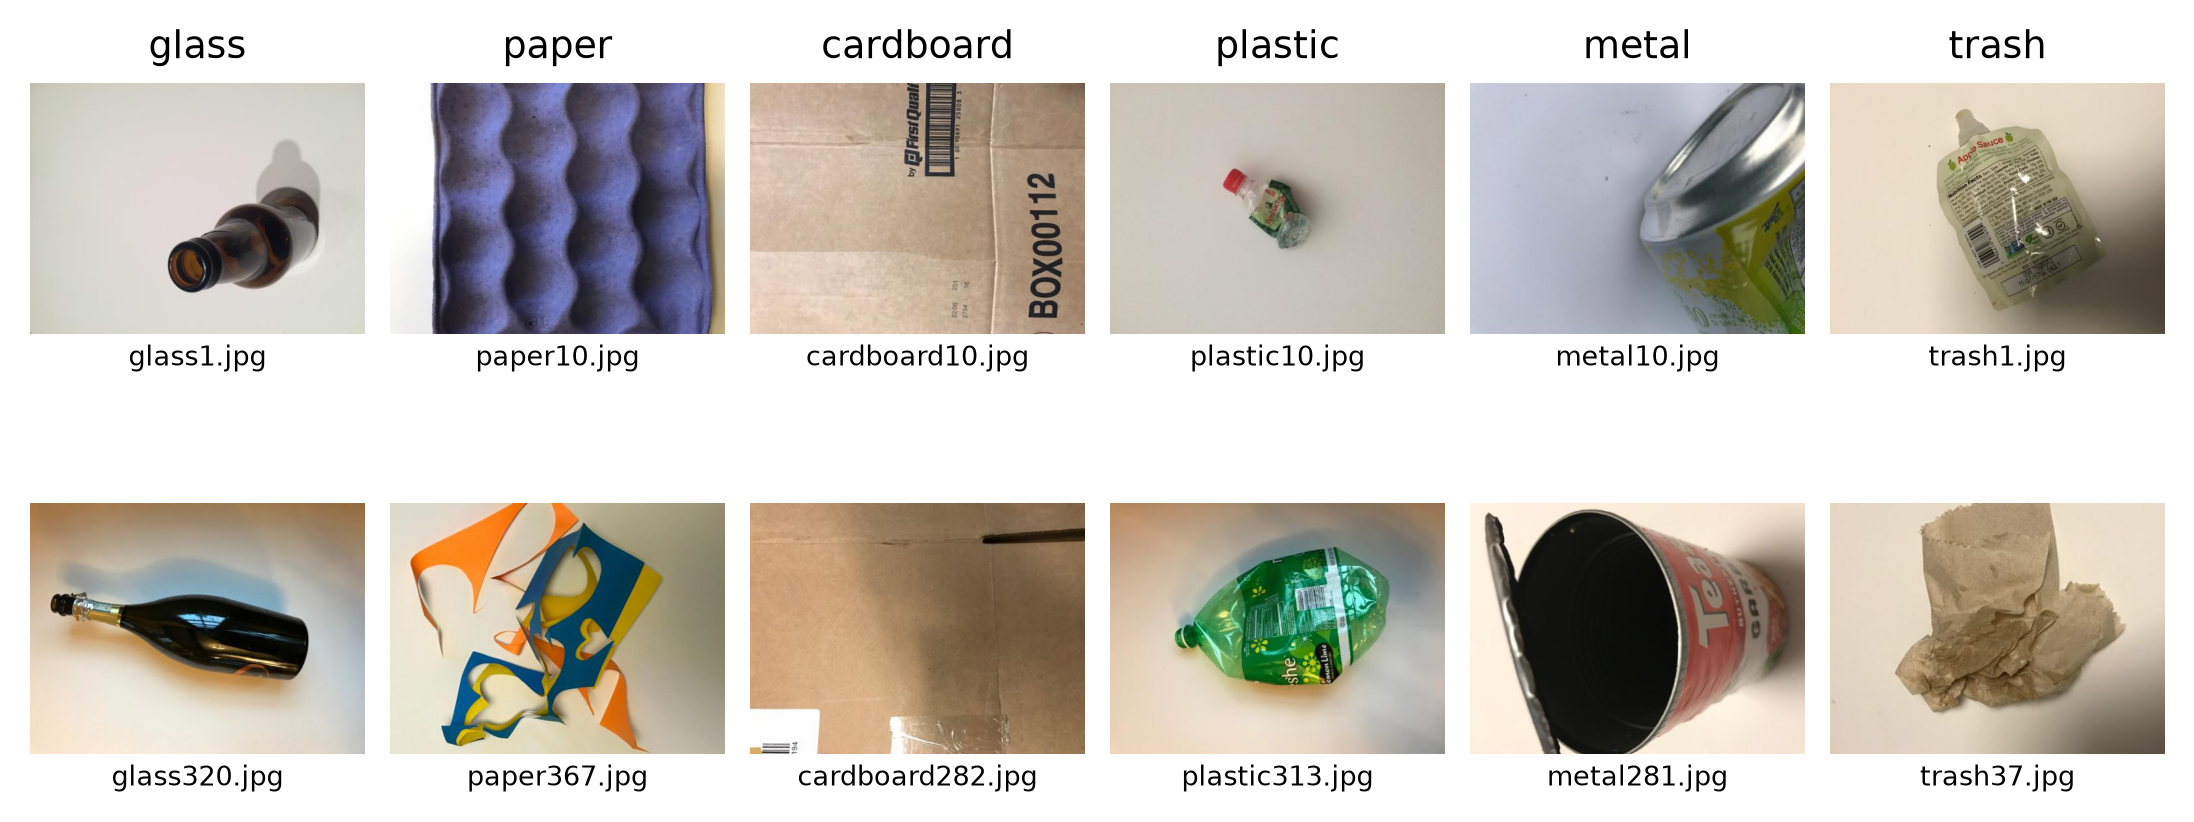

,class_name,path,split
0,glass,glass/glass1.jpg,train
1,glass,glass/glass320.jpg,train
2,paper,paper/paper10.jpg,train
3,paper,paper/paper367.jpg,train
4,cardboard,cardboard/cardboard10.jpg,train
5,cardboard,cardboard/cardboard282.jpg,train
6,plastic,plastic/plastic10.jpg,train
7,plastic,plastic/plastic313.jpg,train
8,metal,metal/metal10.jpg,train
9,metal,metal/metal281.jpg,train


In [5]:
example_records = vis.examples(ROOT, manifest, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig02_exemplos.png'), width=1100))
display(pd.DataFrame(example_records))
assert len(example_records) == 12
assert set(row['split'] for row in example_records) == {'train'}

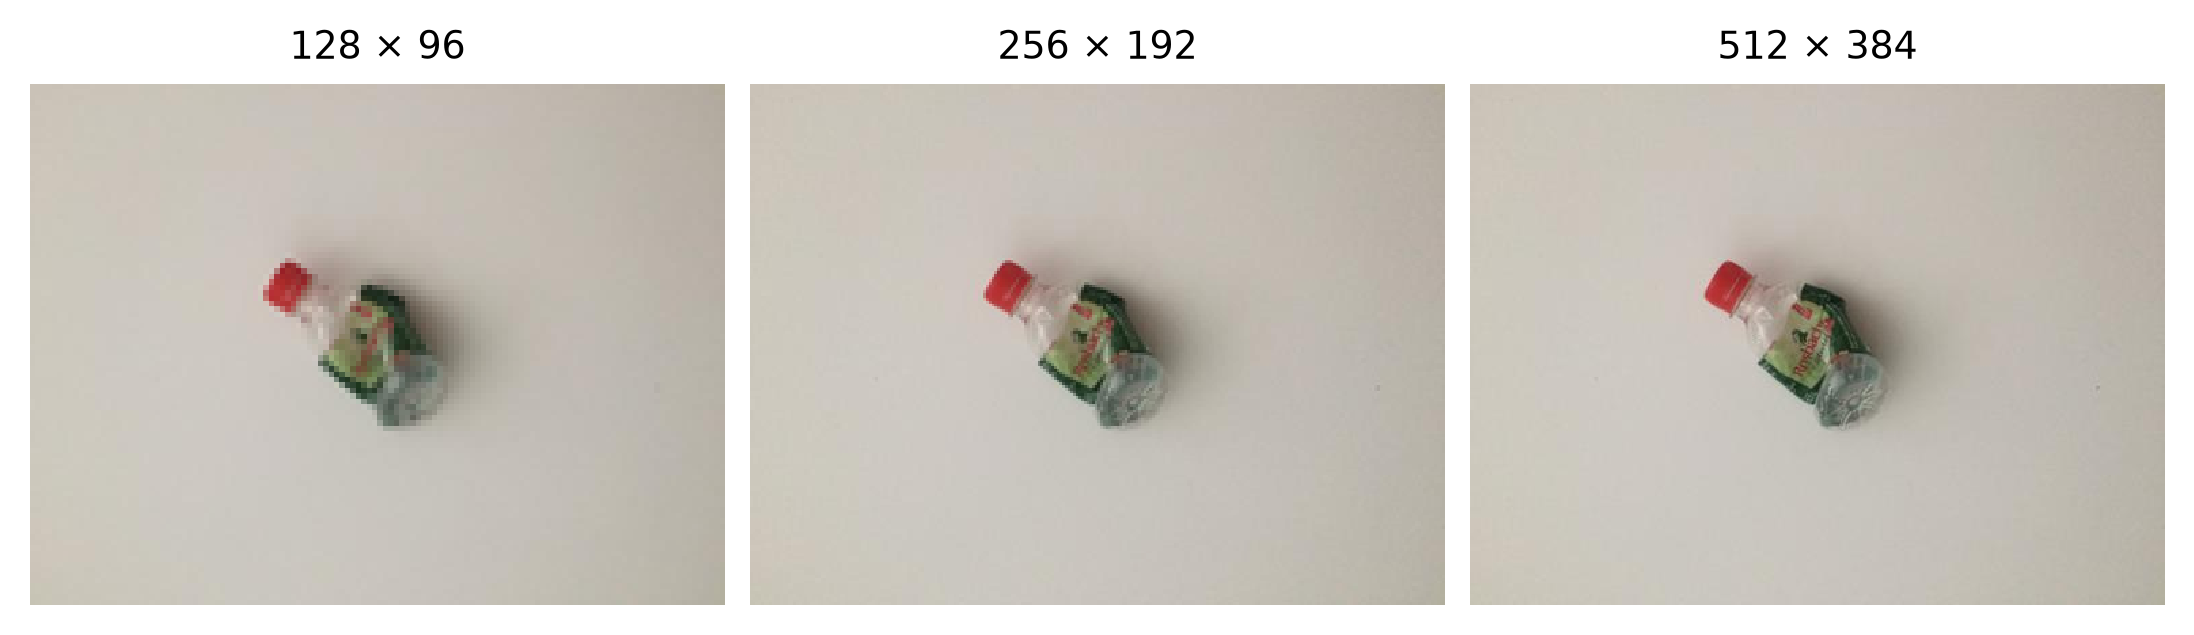

,path,split,display
0,plastic/plastic10.jpg,train,Equal physical panel size; nearest-neighbor di...


In [6]:
resolution_record = vis.resolutions(ROOT, manifest, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig03_resolucoes.png'), width=1100))
display(pd.DataFrame([resolution_record]))

## Configurações e seleção exclusivamente pela validação

O bloqueio registra os hashes dos dados, configurações, modelos, históricos e previsões
de validação. A seleção usa o F1 macro do checkpoint realmente salvo. Empates usam a ordem
fixa dos experimentos. O maior F1 de uma época diferente não substitui o valor do checkpoint.
A melhor CNN é registrada separadamente para eventual extensão YOLO.

In [7]:
from src.evaluate import verify_lock, validate_validation_predictions
lock = verify_lock(ROOT)
summary = pd.read_csv(ROOT / 'reports/summary.csv').set_index('experiment').loc[EXPERIMENTS]
per_class_saved = pd.read_csv(ROOT / 'reports/per_class.csv')
summary_json = json.loads((ROOT / 'reports/summary.json').read_text())
assert summary_json['selection_lock_sha256'] == sha256_file(ROOT / 'selection_lock.json')

validation_rows, configs, metadata = [], [], {}
for experiment in EXPERIMENTS:
    record = json.loads((ROOT / 'runs' / experiment / 'metadata.json').read_text())
    metadata[experiment] = record
    values = validate_validation_predictions(ROOT, experiment, manifest)
    for metric in ['accuracy', 'f1_macro']:
        np.testing.assert_allclose(values[metric], lock['validation_metrics'][experiment][metric], atol=1e-12)
        np.testing.assert_allclose(values[metric], summary.loc[experiment, f'val_{metric}'], atol=1e-12)
    validation_rows.append({'experimento': experiment, **values,
                            'época_salva': record['best_epoch'],
                            'selecionado': experiment == lock['selected_experiment']})
    configs.append({'experimento': experiment, **record['config']})
validation = pd.DataFrame(validation_rows)
expected_selected = max(EXPERIMENTS, key=lambda e: lock['validation_metrics'][e]['f1_macro'])
assert expected_selected == lock['selected_experiment']
display(validation.sort_values('f1_macro', ascending=False, kind='stable'))
display(pd.DataFrame(configs))
print('Bloqueio criado em UTC:', lock['created_at_utc'])
print('Selecionado entre seis:', lock['selected_experiment'])
print('Melhor CNN por validação:', lock['selected_cnn_experiment'])

,experimento,accuracy,f1_macro,support,época_salva,selecionado
3,cnn_128_weighted,0.564644,0.559121,379,17,True
4,cnn_256_unweighted,0.641161,0.551134,379,23,False
5,cnn_512_unweighted,0.651715,0.549302,379,24,False
2,cnn_128_unweighted,0.625330,0.533699,379,17,False
0,mlp_128_unweighted,0.490765,0.394411,379,25,False
1,mlp_128_weighted,0.424802,0.371587,379,25,False


,experimento,seed,batch_size,max_epochs,patience,min_delta,learning_rate,optimizer,weight_decay,dropout,threads,num_workers,normalization,augmentation,checkpoint_metric,selection_metric,device,id,architecture,width,height,class_weights
0,mlp_128_unweighted,42,32,25,5,0.000000,0.000100,Adam,0.000000,0.200000,4,0,RGB uint8 / 255.0,none,val_loss_min,restored_val_f1_macro_max,cpu,mlp_128_unweighted,mlp,128,96,False
1,mlp_128_weighted,42,32,25,5,0.000000,0.000100,Adam,0.000000,0.200000,4,0,RGB uint8 / 255.0,none,val_loss_min,restored_val_f1_macro_max,cpu,mlp_128_weighted,mlp,128,96,True
2,cnn_128_unweighted,42,32,25,5,0.000000,0.000100,Adam,0.000000,0.200000,4,0,RGB uint8 / 255.0,none,val_loss_min,restored_val_f1_macro_max,cpu,cnn_128_unweighted,cnn,128,96,False
3,cnn_128_weighted,42,32,25,5,0.000000,0.000100,Adam,0.000000,0.200000,4,0,RGB uint8 / 255.0,none,val_loss_min,restored_val_f1_macro_max,cpu,cnn_128_weighted,cnn,128,96,True
4,cnn_256_unweighted,42,32,25,5,0.000000,0.000100,Adam,0.000000,0.200000,4,0,RGB uint8 / 255.0,none,val_loss_min,restored_val_f1_macro_max,cpu,cnn_256_unweighted,cnn,256,192,False
5,cnn_512_unweighted,42,32,25,5,0.000000,0.000100,Adam,0.000000,0.200000,4,0,RGB uint8 / 255.0,none,val_loss_min,restored_val_f1_macro_max,cpu,cnn_512_unweighted,cnn,512,384,False


Bloqueio criado em UTC: 2026-10-17T18:56:43.386131+00:00
Selecionado entre seis: cnn_128_weighted
Melhor CNN por validação: cnn_128_weighted


### Busca de configuração, quando realizada

A busca exploratória comparou três taxas comuns à MLP e à CNN em 128×96 sem pesos,
motivada pelo comportamento instável observado na validação inicial. O critério é a
média do F1 macro de validação dos checkpoints restaurados dessas duas arquiteturas;
empates seguem a ordem de candidatos registrada. A busca não consultou o teste.
Esta célula confere os registros existentes; não escolhe novos parâmetros nem treina.

In [8]:
search_root = ROOT / 'search'
trials = pd.read_csv(search_root / 'validation_trials.csv')
search_protocol = json.loads((search_root / 'protocol.json').read_text())
search_selection = json.loads((search_root / 'selection.json').read_text())
assert search_protocol['test_used'] is False and search_selection['test_used'] is False
assert search_selection['decision_before_final_test'] is True
candidate_rates = search_protocol['candidate_learning_rates']
assert len(trials) == 2 * len(candidate_rates)
rate_folders = {0.001:'lr_1e-3', 0.0003:'lr_3e-4', 0.0001:'lr_1e-4'}
scores = {}
for rate in candidate_rates:
    subset = trials[np.isclose(trials.learning_rate, rate)]
    assert set(subset.experiment) == {'mlp_128_unweighted','cnn_128_unweighted'}
    assert len(subset) == 2
    for trial in subset.itertuples(index=False):
        trial_root = search_root / rate_folders[rate]
        vals = validate_validation_predictions(trial_root, trial.experiment, manifest)
        np.testing.assert_allclose(vals['f1_macro'], trial.val_f1_macro, atol=1e-12)
        np.testing.assert_allclose(vals['accuracy'], trial.val_accuracy, atol=1e-12)
    scores[rate] = subset.val_f1_macro.mean()
    np.testing.assert_allclose(scores[rate], search_selection['mean_val_f1_by_rate'][str(rate)], atol=1e-12)
chosen_rate = max(candidate_rates, key=lambda rate:scores[rate])
assert chosen_rate == search_selection['selected_learning_rate']
assert all(record['config']['learning_rate'] == chosen_rate for record in metadata.values())
display(trials)
display(pd.DataFrame([{'taxa':rate,'F1_macro_validação_médio':score,
                       'selecionada':rate == chosen_rate} for rate,score in scores.items()]))
print('Taxa comum da configuração final:', chosen_rate)
print('Busca exploratória separada dos seis resultados finais; não é validação externa.')

,learning_rate,architecture,experiment,val_f1_macro,val_accuracy,best_epoch,epochs,seconds
0,0.001000,mlp,mlp_128_unweighted,0.138495,0.287599,8,13,30.404979
1,0.001000,cnn,cnn_128_unweighted,0.507841,0.585752,8,13,41.250438
2,0.000300,mlp,mlp_128_unweighted,0.301273,0.395778,10,15,39.547818
3,0.000300,cnn,cnn_128_unweighted,0.535573,0.620053,9,14,55.435796
4,0.000100,mlp,mlp_128_unweighted,0.394411,0.490765,25,25,75.855707
5,0.000100,cnn,cnn_128_unweighted,0.533699,0.625330,17,22,61.714416


,taxa,F1_macro_validação_médio,selecionada
0,0.001000,0.323168,False
1,0.000300,0.418423,False
2,0.000100,0.464055,True


Taxa comum da configuração final: 0.0001
Busca exploratória separada dos seis resultados finais; não é validação externa.


## Auditoria independente das métricas a partir das previsões

Para cada classe, precisão = TP/(TP+FP), recall = TP/(TP+FN) e
F1 = 2TP/(2TP+FP+FN). O F1 macro é a média simples dos seis F1; cada classe tem
a mesma importância. Suporte é a quantidade de imagens reais da classe.

Usa-se `zero_division=0`: uma métrica indefinida recebe zero, com todas as seis classes
mantidas no cálculo. Isso não corrige falhas do classificador. A célula informa classes
nunca previstas, que podem ter precisão indefinida por ausência de previsões positivas.

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
expected_test = manifest.loc[manifest.split == 'test'].set_index('path')
predictions, metrics, recomputed_rows, recomputed_per_class = {}, {}, [], []
for experiment in EXPERIMENTS:
    run = ROOT / 'runs' / experiment
    frame = pd.read_csv(run / 'predictions.csv')
    stored = json.loads((run / 'metrics.json').read_text())
    assert stored['selection_lock_sha256'] == sha256_file(ROOT / 'selection_lock.json')
    assert stored['predictions_sha256'] == sha256_file(run / 'predictions.csv')
    assert stored['checkpoint_sha256'] == sha256_file(run / 'model.pt')
    assert pd.Timestamp(stored['evaluated_at_utc']) >= pd.Timestamp(lock['created_at_utc'])
    assert frame.path.is_unique and set(frame.path) == set(expected_test.index)
    frame = frame.set_index('path').loc[expected_test.index].reset_index()
    np.testing.assert_array_equal(frame.y_true.to_numpy(), expected_test.label.to_numpy())
    assert frame.y_pred.isin(range(6)).all()
    probs = frame[[f'prob_{name}' for name in CLASSES]].to_numpy()
    assert np.isfinite(probs).all() and (probs >= 0).all() and (probs <= 1).all()
    np.testing.assert_allclose(probs.sum(1), 1, atol=1e-5)
    np.testing.assert_array_equal(probs.argmax(1), frame.y_pred.to_numpy())
    np.testing.assert_allclose(probs[np.arange(len(frame)), frame.y_pred.to_numpy()],
                               frame.pred_probability.to_numpy(), atol=1e-7)
    report = classification_report(frame.y_true, frame.y_pred, labels=range(6),
                                    target_names=CLASSES, zero_division=0, output_dict=True)
    accuracy = accuracy_score(frame.y_true, frame.y_pred)
    macro_f1 = f1_score(frame.y_true, frame.y_pred, labels=range(6), average='macro', zero_division=0)
    cm = confusion_matrix(frame.y_true, frame.y_pred, labels=range(6))
    row_percent = 100 * cm / cm.sum(axis=1, keepdims=True)
    np.testing.assert_allclose([accuracy, macro_f1], [stored['accuracy'], stored['f1_macro']], atol=1e-12)
    np.testing.assert_allclose([accuracy, macro_f1], summary.loc[experiment, ['test_accuracy','test_f1_macro']].to_numpy(dtype=float), atol=1e-12)
    np.testing.assert_array_equal(cm, stored['confusion_count'])
    np.testing.assert_allclose(row_percent, stored['confusion_row_percent'], atol=1e-10)
    assert int(stored['support']) == len(expected_test) == int(summary.loc[experiment, 'test_support'])
    np.testing.assert_allclose(macro_f1, np.mean([report[name]['f1-score'] for name in CLASSES]), atol=1e-12)
    predictions[experiment], metrics[experiment] = frame, stored
    recomputed_rows.append({'experimento':experiment, 'acurácia':accuracy,
                            'F1_macro':macro_f1, 'suporte':len(frame)})
    for name in CLASSES:
        values = report[name]
        saved_row = per_class_saved[(per_class_saved.experiment == experiment) & (per_class_saved.class_name == name)]
        assert len(saved_row) == 1
        np.testing.assert_allclose([values['precision'], values['recall'], values['f1-score'], values['support']],
            saved_row[['precision','recall','f1','support']].iloc[0].to_numpy(dtype=float), atol=1e-12)
        for key in ['precision','recall','f1-score','support']:
            np.testing.assert_allclose(values[key], stored['classification_report'][name][key], atol=1e-12)
        recomputed_per_class.append({'experimento':experiment, 'classe':name,
            'precisão':values['precision'], 'recall':values['recall'], 'F1':values['f1-score'],
            'suporte':int(values['support'])})
    never_predicted = [CLASSES[i] for i in range(6) if cm[:,i].sum() == 0]
    if never_predicted:
        print(experiment, '— classes nunca previstas:', ', '.join(never_predicted))
recomputed = pd.DataFrame(recomputed_rows)
per_class = pd.DataFrame(recomputed_per_class)
assert len(per_class) == 36
display(recomputed)
print('As métricas das previsões coincidem com metrics.json, summary.csv e per_class.csv.')

mlp_128_unweighted — classes nunca previstas: trash
cnn_128_unweighted — classes nunca previstas: trash


cnn_256_unweighted — classes nunca previstas: trash
cnn_512_unweighted — classes nunca previstas: trash


,experimento,acurácia,F1_macro,suporte
0,mlp_128_unweighted,0.444737,0.358337,380
1,mlp_128_weighted,0.384211,0.330402,380
2,cnn_128_unweighted,0.618421,0.524142,380
3,cnn_128_weighted,0.581579,0.571847,380
4,cnn_256_unweighted,0.592105,0.513089,380
5,cnn_512_unweighted,0.621053,0.522251,380


As métricas das previsões coincidem com metrics.json, summary.csv e per_class.csv.


## Métricas por classe — seis modelos e seis classes

In [10]:
for experiment in EXPERIMENTS:
    display(Markdown(f'**{vis.DISPLAY[experiment]}**'))
    display(per_class.loc[per_class.experimento == experiment].drop(columns='experimento').reset_index(drop=True))

**MLP · 128 × 96 · sem pesos**

,classe,precisão,recall,F1,suporte
0,glass,0.375000,0.118421,0.180000,76
1,paper,0.504673,0.606742,0.551020,89
2,cardboard,0.719298,0.683333,0.700855,60
3,plastic,0.337662,0.712329,0.458150,73
4,metal,0.342105,0.209677,0.260000,62
5,trash,0.000000,0.000000,0.000000,20


**MLP · 128 × 96 · com pesos**

,classe,precisão,recall,F1,suporte
0,glass,0.000000,0.000000,0.000000,76
1,paper,0.533333,0.449438,0.487805,89
2,cardboard,0.616667,0.616667,0.616667,60
3,plastic,0.331250,0.726027,0.454936,73
4,metal,0.147059,0.080645,0.104167,62
5,trash,0.224490,0.550000,0.318841,20


**CNN · 128 × 96 · sem pesos**

...

,classe,precisão,recall,F1,suporte
0,glass,0.507692,0.434211,0.468085,76
1,paper,0.803571,0.505618,0.620690,89
2,cardboard,0.867925,0.766667,0.814159,60
3,plastic,0.586207,0.698630,0.637500,73
4,metal,0.457143,0.516129,0.484848,62
5,trash,0.285714,0.700000,0.405797,20


**CNN · 256 × 192 · sem pesos**

,classe,precisão,recall,F1,suporte
0,glass,0.387931,0.592105,0.468750,76
1,paper,0.688889,0.696629,0.692737,89
2,cardboard,0.836364,0.766667,0.800000,60
3,plastic,0.681818,0.616438,0.647482,73
4,metal,0.509434,0.435484,0.469565,62
5,trash,0.000000,0.000000,0.000000,20


**CNN · 512 × 384 · sem pesos**

,classe,precisão,recall,F1,suporte
0,glass,0.488636,0.565789,0.524390,76
1,paper,0.593750,0.853933,0.700461,89
2,cardboard,0.790323,0.816667,0.803279,60
3,plastic,0.643836,0.643836,0.643836,73
4,metal,0.724138,0.338710,0.461538,62
5,trash,0.000000,0.000000,0.000000,20


## Custo medido e histórico do treinamento

O tamanho mostrado é o do checkpoint final `model.pt`, não de arquivos de retomada.
MiB usa 1024² bytes. O pico RSS é memória do processo amostrada, não memória da GPU.
Leia os métodos de medição e as informações de hardware abaixo; valores de GPU ausentes
não significam consumo nulo. Tempo total e média por época precisam ser interpretados
junto do número de épocas e do critério de parada.

In [11]:
cost_rows, history_rows = [], []
for experiment in EXPERIMENTS:
    record, row = metadata[experiment], summary.loc[experiment]
    np.testing.assert_allclose(row['train_seconds'], record['total_training_seconds'], atol=1e-8)
    np.testing.assert_allclose(row['peak_rss_mb'], record['peak_rss_bytes'] / 1024**2, atol=1e-8)
    assert int(row['checkpoint_bytes']) == (ROOT / 'runs' / experiment / 'model.pt').stat().st_size
    assert int(row['parameters']) == record['parameters']
    assert int(row['batch_size']) == record['config']['batch_size']
    history = vis.history_frame(ROOT, experiment)
    assert len(history) == record['epochs_completed']
    assert int(record['best_epoch']) in history.epoch.to_numpy()
    assert np.isfinite(history[['train_loss','val_loss','train_accuracy','val_accuracy']]).all().all()
    cost_rows.append({'experimento':experiment, 'parâmetros':record['parameters'],
        'modelo_MiB':row['checkpoint_bytes']/1024**2, 'épocas':record['epochs_completed'],
        'época_salva':record['best_epoch'], 'lote':row['batch_size'],
        'tempo_total_s':row['train_seconds'], 'tempo_médio_época_s':row['mean_epoch_seconds'],
        'pico_RSS_MiB':row['peak_rss_mb'], 'pico_GPU_MiB':row['peak_gpu_mb']})
    history_rows.append(history.assign(experiment=experiment))
costs = pd.DataFrame(cost_rows)
histories = pd.concat(history_rows, ignore_index=True)
display(costs)
for experiment, record in metadata.items():
    display(Markdown(f'**{vis.DISPLAY[experiment]}**'))
    print('Hardware:', json.dumps(record['hardware'], ensure_ascii=False))
    print('Tempo:', record['timing_method'])
    print('Memória:', record['memory_method'])
    print('Treino versus validação:', record['training_metric_note'])

,experimento,parâmetros,modelo_MiB,épocas,época_salva,lote,tempo_total_s,tempo_médio_época_s,pico_RSS_MiB,pico_GPU_MiB
0,mlp_128_unweighted,4727366,18.036530,25,25,32,56.679903,2.267196,661.226562,NaN
1,mlp_128_weighted,4727366,18.036530,25,25,32,60.380389,2.415216,662.878906,NaN
2,cnn_128_unweighted,24086,0.099549,22,17,32,49.173258,2.235148,596.113281,NaN
3,cnn_128_weighted,24086,0.099549,22,17,32,50.880779,2.312763,594.234375,NaN
4,cnn_256_unweighted,24086,0.099549,25,23,32,216.538856,8.661554,1015.453125,NaN
5,cnn_512_unweighted,24086,0.099549,25,24,32,1258.552134,50.342085,2371.757812,NaN


**MLP · 128 × 96 · sem pesos**

Hardware: {"cpu": "11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz", "physical_cores": 4, "logical_cores": 8, "system_ram_bytes": 15854059520, "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43", "python": "3.12.14", "torch": "2.14.1+cpu", "numpy": "2.3.5", "device": "cpu", "gpu_used": false}
Tempo: perf_counter: loop de treino, validação por época e checkpoints; exclui download, cache, inicialização e avaliação do checkpoint restaurado.
Memória: RSS absoluto do processo, psutil, amostragem 50 ms; inclui páginas do cache mapeadas; sem GPU.
Treino versus validação: Métricas de treino agregadas durante atualizações, com dropout ativo; validação em eval(). Perdas ponderadas normalizadas pela soma dos pesos observados.


**MLP · 128 × 96 · com pesos**

Hardware: {"cpu": "11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz", "physical_cores": 4, "logical_cores": 8, "system_ram_bytes": 15854059520, "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43", "python": "3.12.14", "torch": "2.14.1+cpu", "numpy": "2.3.5", "device": "cpu", "gpu_used": false}
Tempo: perf_counter: loop de treino, validação por época e checkpoints; exclui download, cache, inicialização e avaliação do checkpoint restaurado.
Memória: RSS absoluto do processo, psutil, amostragem 50 ms; inclui páginas do cache mapeadas; sem GPU.
Treino versus validação: Métricas de treino agregadas durante atualizações, com dropout ativo; validação em eval(). Perdas ponderadas normalizadas pela soma dos pesos observados.


...

Hardware: {"cpu": "11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz", "physical_cores": 4, "logical_cores": 8, "system_ram_bytes": 15854059520, "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43", "python": "3.12.14", "torch": "2.14.1+cpu", "numpy": "2.3.5", "device": "cpu", "gpu_used": false}
Tempo: perf_counter: loop de treino, validação por época e checkpoints; exclui download, cache, inicialização e avaliação do checkpoint restaurado.
Memória: RSS absoluto do processo, psutil, amostragem 50 ms; inclui páginas do cache mapeadas; sem GPU.
Treino versus validação: Métricas de treino agregadas durante atualizações, com dropout ativo; validação em eval(). Perdas ponderadas normalizadas pela soma dos pesos observados.


**CNN · 256 × 192 · sem pesos**

Hardware: {"cpu": "11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz", "physical_cores": 4, "logical_cores": 8, "system_ram_bytes": 15854059520, "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43", "python": "3.12.14", "torch": "2.14.1+cpu", "numpy": "2.3.5", "device": "cpu", "gpu_used": false}
Tempo: perf_counter: loop de treino, validação por época e checkpoints; exclui download, cache, inicialização e avaliação do checkpoint restaurado.
Memória: RSS absoluto do processo, psutil, amostragem 50 ms; inclui páginas do cache mapeadas; sem GPU.
Treino versus validação: Métricas de treino agregadas durante atualizações, com dropout ativo; validação em eval(). Perdas ponderadas normalizadas pela soma dos pesos observados.


**CNN · 512 × 384 · sem pesos**

Hardware: {"cpu": "11th Gen Intel(R) Core(TM) i3-1125G4 @ 2.00GHz", "physical_cores": 4, "logical_cores": 8, "system_ram_bytes": 15854059520, "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43", "python": "3.12.14", "torch": "2.14.1+cpu", "numpy": "2.3.5", "device": "cpu", "gpu_used": false}
Tempo: perf_counter: loop de treino, validação por época e checkpoints; exclui download, cache, inicialização e avaliação do checkpoint restaurado.
Memória: RSS absoluto do processo, psutil, amostragem 50 ms; inclui páginas do cache mapeadas; sem GPU.
Treino versus validação: Métricas de treino agregadas durante atualizações, com dropout ativo; validação em eval(). Perdas ponderadas normalizadas pela soma dos pesos observados.


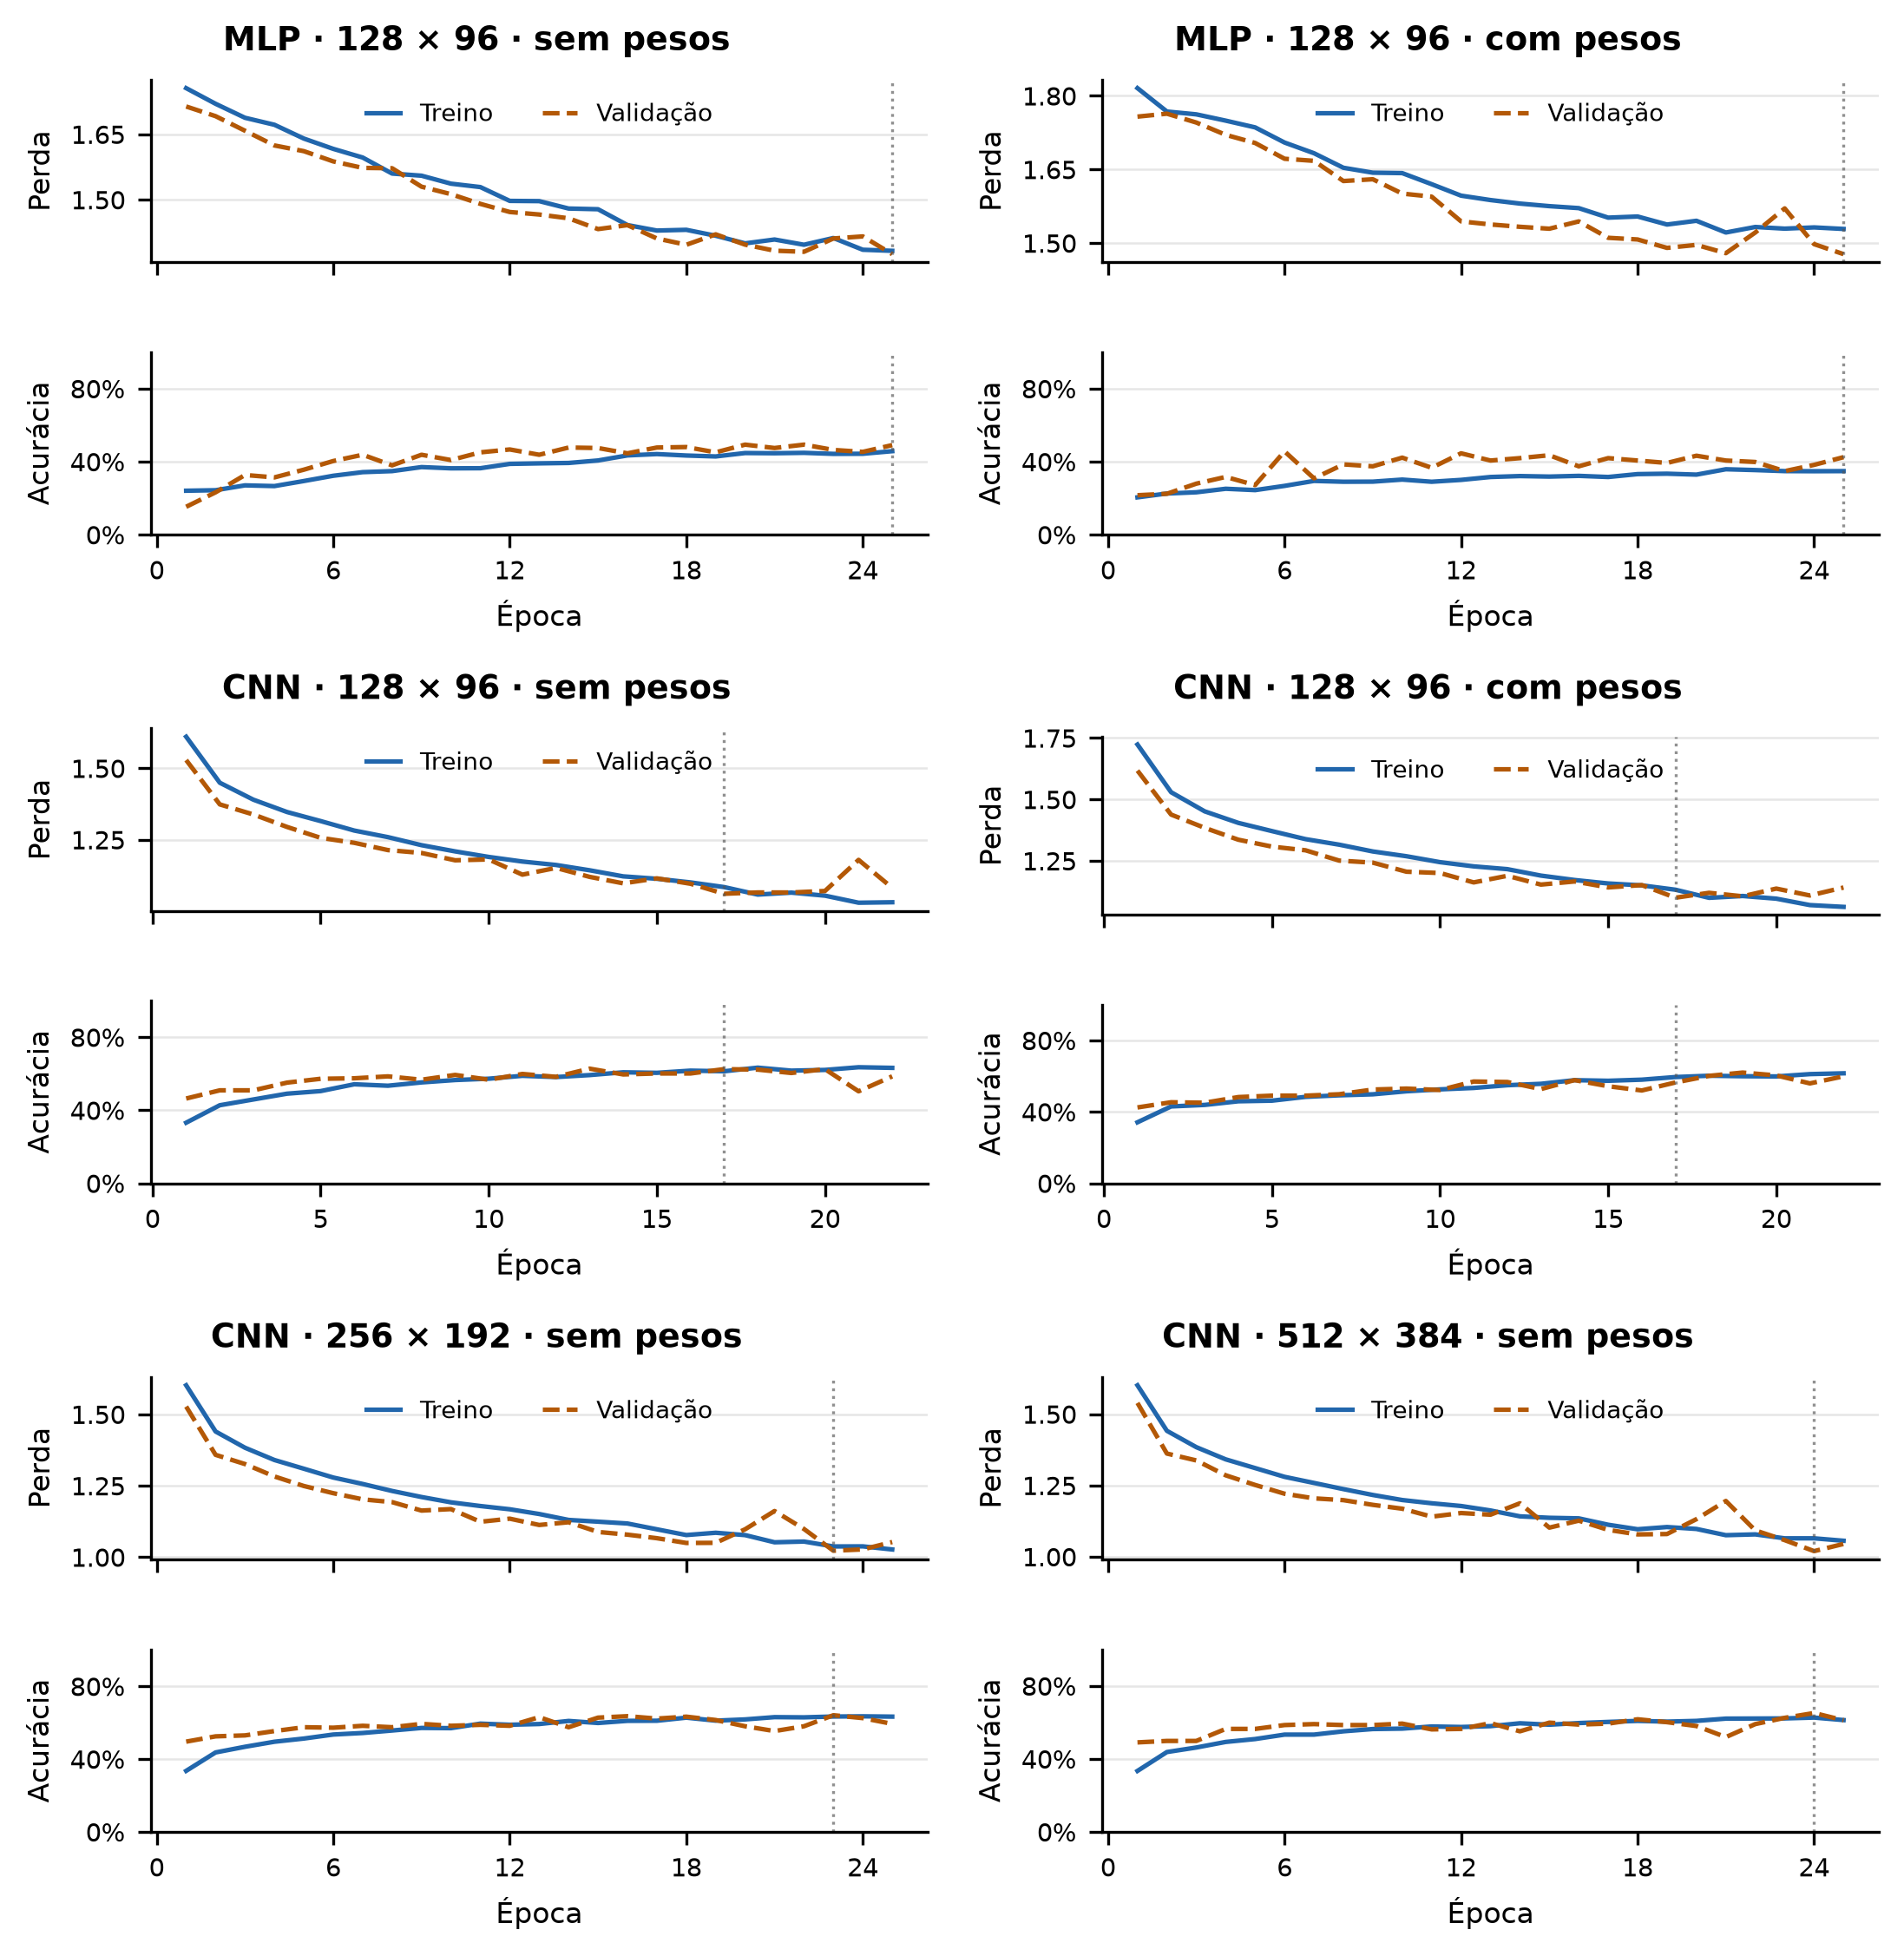

Linha pontilhada vertical: época do checkpoint recuperado.


In [12]:
vis.learning_curves(ROOT, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig04_curvas_aprendizagem.png'), width=1100))
print('Linha pontilhada vertical: época do checkpoint recuperado.')

## Matrizes de confusão

Reais nas linhas, previstas nas colunas. Cada célula mostra a contagem e o percentual
relativo ao suporte da classe real. Uma linha soma aproximadamente 100% após arredondamento.
A diagonal representa acertos. A ordem é `glass, paper, cardboard, plastic, metal, trash`.

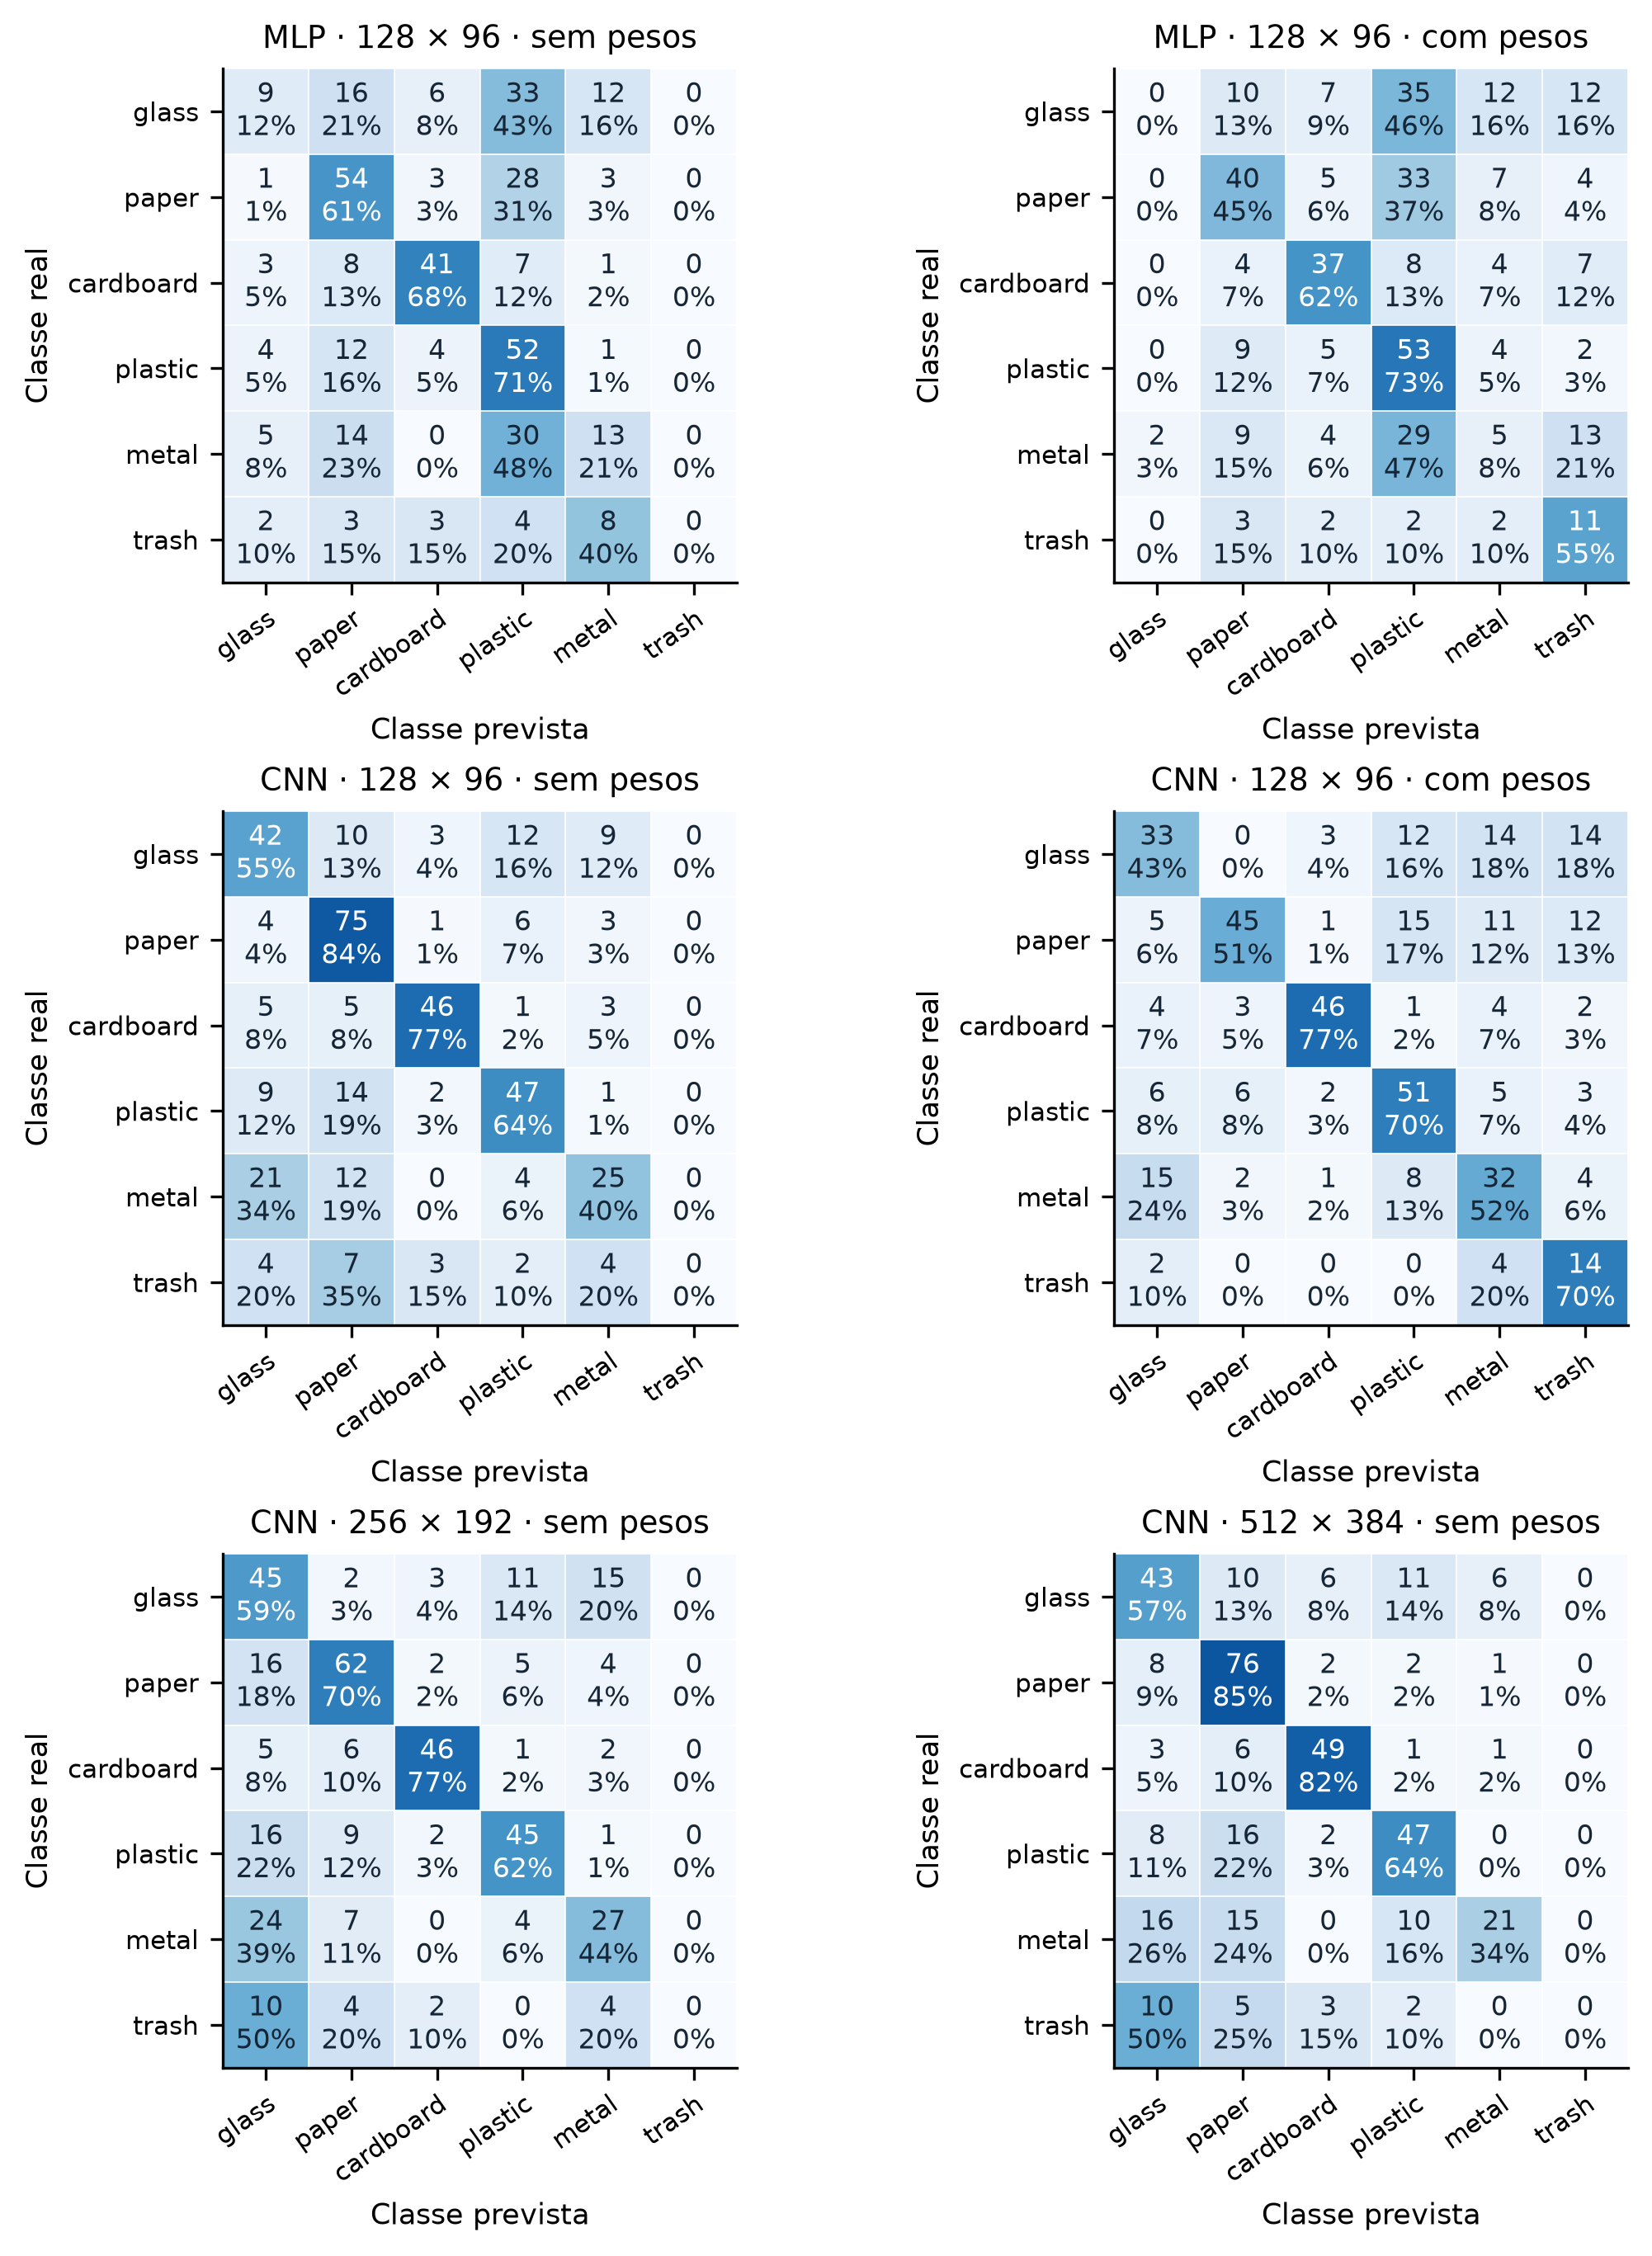

In [13]:
vis.confusions(ROOT, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig05_matrizes_confusao.png'), width=1100))

## Efeito dos pesos de classe em 128×96

As diferenças abaixo são **com pesos menos sem pesos**, em pontos percentuais.
A tabela por classe permite identificar ganhos e perdas, especialmente em `trash`.
Como há uma semente principal, os sinais observados não demonstram estabilidade em novas execuções.

In [14]:
weighted_effect, class_effect = [], []
for architecture in ['mlp','cnn']:
    plain, weighted = f'{architecture}_128_unweighted', f'{architecture}_128_weighted'
    weighted_effect.append({'arquitetura':architecture.upper(),
        'delta_acurácia_pp':100*(summary.loc[weighted,'test_accuracy']-summary.loc[plain,'test_accuracy']),
        'delta_F1_macro_pp':100*(summary.loc[weighted,'test_f1_macro']-summary.loc[plain,'test_f1_macro'])})
    left = per_class[per_class.experimento == plain].set_index('classe')
    right = per_class[per_class.experimento == weighted].set_index('classe')
    for name in CLASSES:
        class_effect.append({'arquitetura':architecture.upper(), 'classe':name,
            **{f'delta_{metric}_pp':100*(right.loc[name,metric]-left.loc[name,metric])
               for metric in ['precisão','recall','F1']}, 'suporte':int(left.loc[name,'suporte'])})
display(pd.DataFrame(weighted_effect))
display(pd.DataFrame(class_effect))

,arquitetura,delta_acurácia_pp,delta_F1_macro_pp
0,MLP,-6.052632,-2.793508
1,CNN,-3.684211,4.770463


,arquitetura,classe,delta_precisão_pp,delta_recall_pp,delta_F1_pp,suporte
0,MLP,glass,-37.500000,-11.842105,-18.000000,76
1,MLP,paper,2.866044,-15.730337,-6.321553,89
2,MLP,cardboard,-10.263158,-6.666667,-8.418803,60
3,MLP,plastic,-0.641234,1.369863,-0.321416,73
4,MLP,metal,-19.504644,-12.903226,-15.583333,62
5,MLP,trash,22.448980,55.000000,31.884058,20
6,CNN,glass,1.357466,-11.842105,-5.365402,76
7,CNN,paper,19.381533,-33.707865,-8.685751,89
8,CNN,cardboard,3.156089,0.000000,1.415929,60
9,CNN,plastic,-6.657088,5.479452,-1.077586,73


## Efeito da resolução e intervalos de incerteza

Só entram as três CNNs sem pesos. Os intervalos, quando disponíveis, são percentis de
bootstrap estratificado do teste, condicionais aos modelos já treinados e aos suportes
observados. Eles não representam variação por semente, treinamento ou domínio externo;
não servem isoladamente para afirmar significância de diferenças entre modelos.

,experimento,métrica,estimativa,limite_inferior,limite_superior,repetições,semente,confiança
0,mlp_128_unweighted,accuracy,0.444737,0.400000,0.486842,2000,20261127,0.950000
1,mlp_128_unweighted,f1_macro,0.358337,0.318517,0.397341,2000,20261127,0.950000
2,mlp_128_weighted,accuracy,0.384211,0.344737,0.426316,2000,20261127,0.950000
3,mlp_128_weighted,f1_macro,0.330402,0.291001,0.369808,2000,20261127,0.950000
4,cnn_128_unweighted,accuracy,0.618421,0.573684,0.663158,2000,20261127,0.950000
5,cnn_128_unweighted,f1_macro,0.524142,0.483974,0.563997,2000,20261127,0.950000
6,cnn_128_weighted,accuracy,0.581579,0.534211,0.628947,2000,20261127,0.950000
7,cnn_128_weighted,f1_macro,0.571847,0.524267,0.618123,2000,20261127,0.950000
8,cnn_256_unweighted,accuracy,0.592105,0.544737,0.636842,2000,20261127,0.950000
9,cnn_256_unweighted,f1_macro,0.513089,0.474591,0.550201,2000,20261127,0.950000


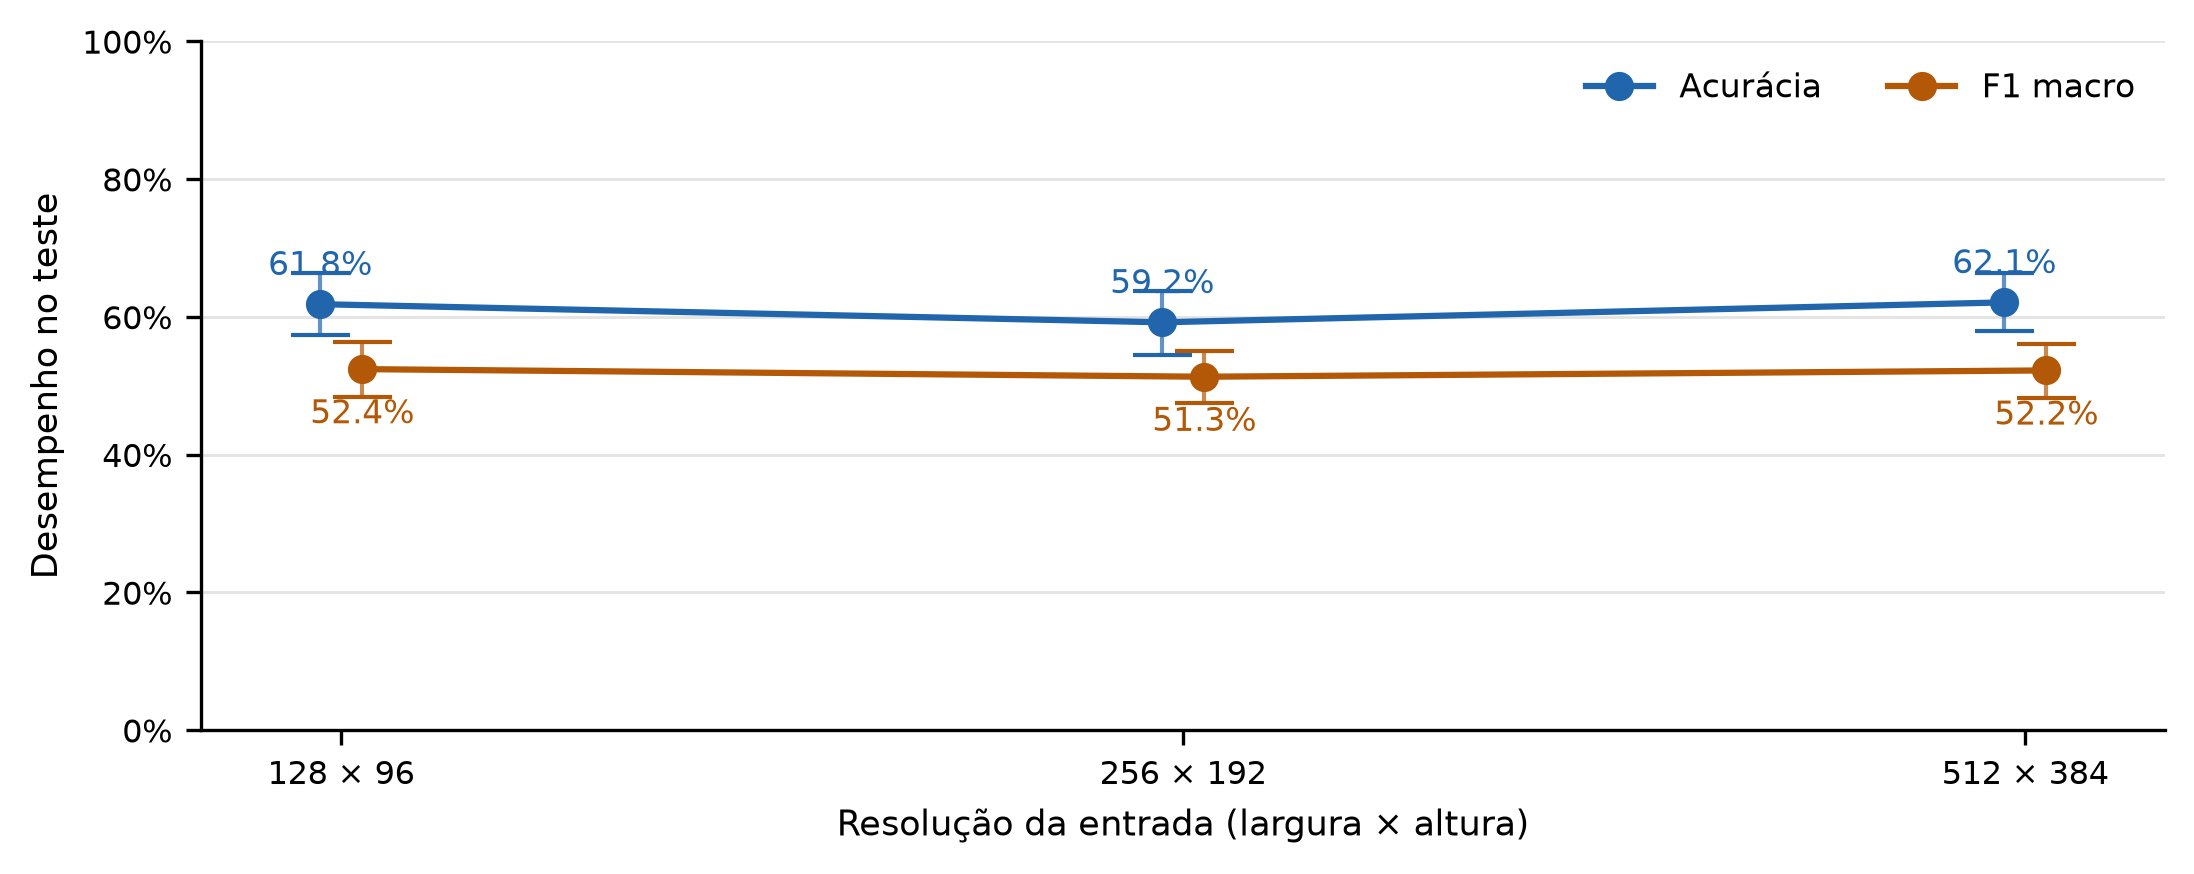

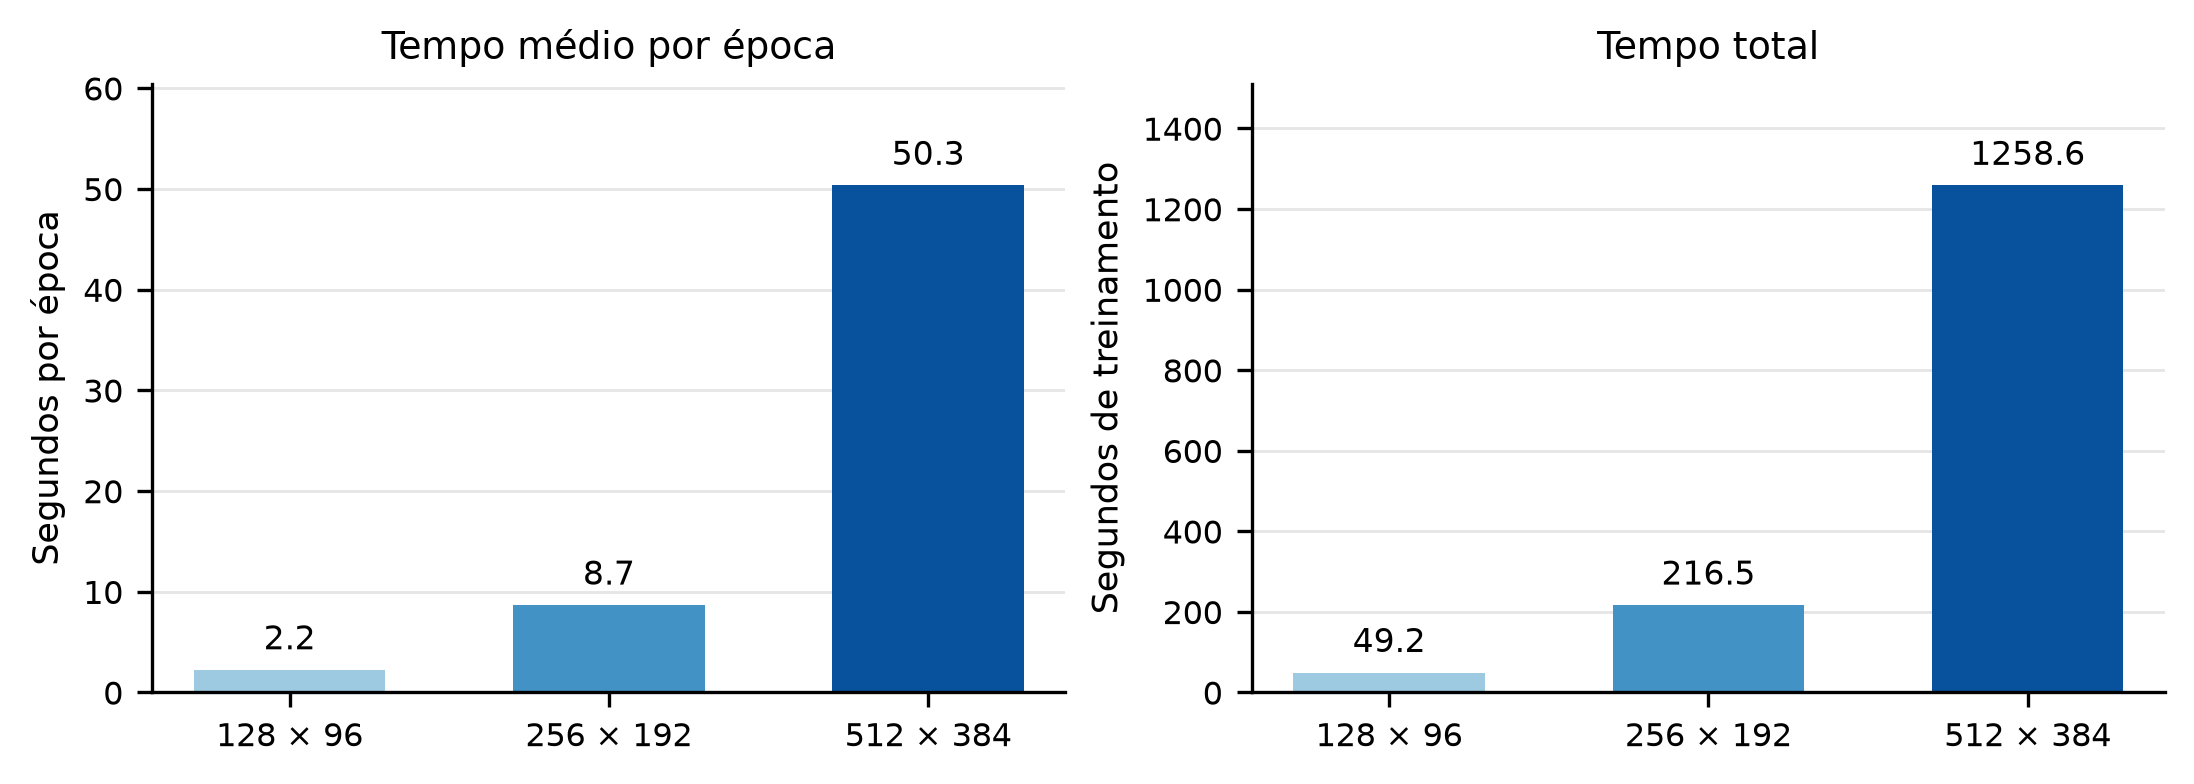

,test_accuracy,test_f1_macro,parameters,epochs_completed,train_seconds,mean_epoch_seconds,peak_rss_mb,tempo_época_relativo_128,tempo_total_relativo_128
experiment,,,,,,,,,
cnn_128_unweighted,0.618421,0.524142,24086,22,49.173258,2.235148,596.113281,1.000000,1.000000
cnn_256_unweighted,0.592105,0.513089,24086,25,216.538856,8.661554,1015.453125,3.875159,4.403590
cnn_512_unweighted,0.621053,0.522251,24086,25,1258.552134,50.342085,2371.757812,22.522931,25.594239


In [15]:
interval_rows = []
for experiment in EXPERIMENTS:
    ci = metrics[experiment].get('bootstrap_95ci')
    if ci:
        for measure in ['accuracy','f1_macro']:
            interval_rows.append({'experimento':experiment, 'métrica':measure,
                'estimativa':metrics[experiment][measure], 'limite_inferior':ci[measure][0],
                'limite_superior':ci[measure][1], 'repetições':ci['repetitions'],
                'semente':ci['seed'], 'confiança':ci['confidence_level']})
if interval_rows:
    display(pd.DataFrame(interval_rows))
else:
    print('Esta avaliação não contém intervalos de bootstrap.')
vis.resolution_metrics(ROOT, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig06_resolucao_desempenho.png'), width=1100))
vis.resolution_cost(ROOT, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig07_resolucao_custo.png'), width=1100))
resolution_ids = [f'cnn_{width}_unweighted' for width in [128,256,512]]
resolution_table = summary.loc[resolution_ids,
    ['test_accuracy','test_f1_macro','parameters','epochs_completed','train_seconds','mean_epoch_seconds','peak_rss_mb']].copy()
resolution_table['tempo_época_relativo_128'] = resolution_table.mean_epoch_seconds / resolution_table.iloc[0].mean_epoch_seconds
resolution_table['tempo_total_relativo_128'] = resolution_table.train_seconds / resolution_table.iloc[0].train_seconds
display(resolution_table)
assert resolution_table.parameters.nunique() == 1

## Erros do modelo selecionado pela validação

O modelo é escolhido antes do teste. Para a inspeção, mostram-se até seis erros com maior
probabilidade atribuída à classe prevista, com desempate pelo caminho do arquivo.
A seleção dos exemplos ocorre apenas para análise, sem ajuste posterior do modelo.
Probabilidade softmax não é garantia de confiança calibrada. Se houver menos de seis erros,
todos aparecem; se não houver erros, o resultado é declarado.

Modelo: CNN · 128 × 96 · com pesos
Erros no teste: 159 de 380 imagens.


,path,true_class,pred_class,pred_probability
0,plastic/plastic364.jpg,plastic,paper,0.700655
1,glass/glass501.jpg,glass,plastic,0.684726
2,cardboard/cardboard33.jpg,cardboard,plastic,0.665280
3,metal/metal37.jpg,metal,plastic,0.659360
4,glass/glass499.jpg,glass,plastic,0.613108
5,cardboard/cardboard239.jpg,cardboard,paper,0.611933


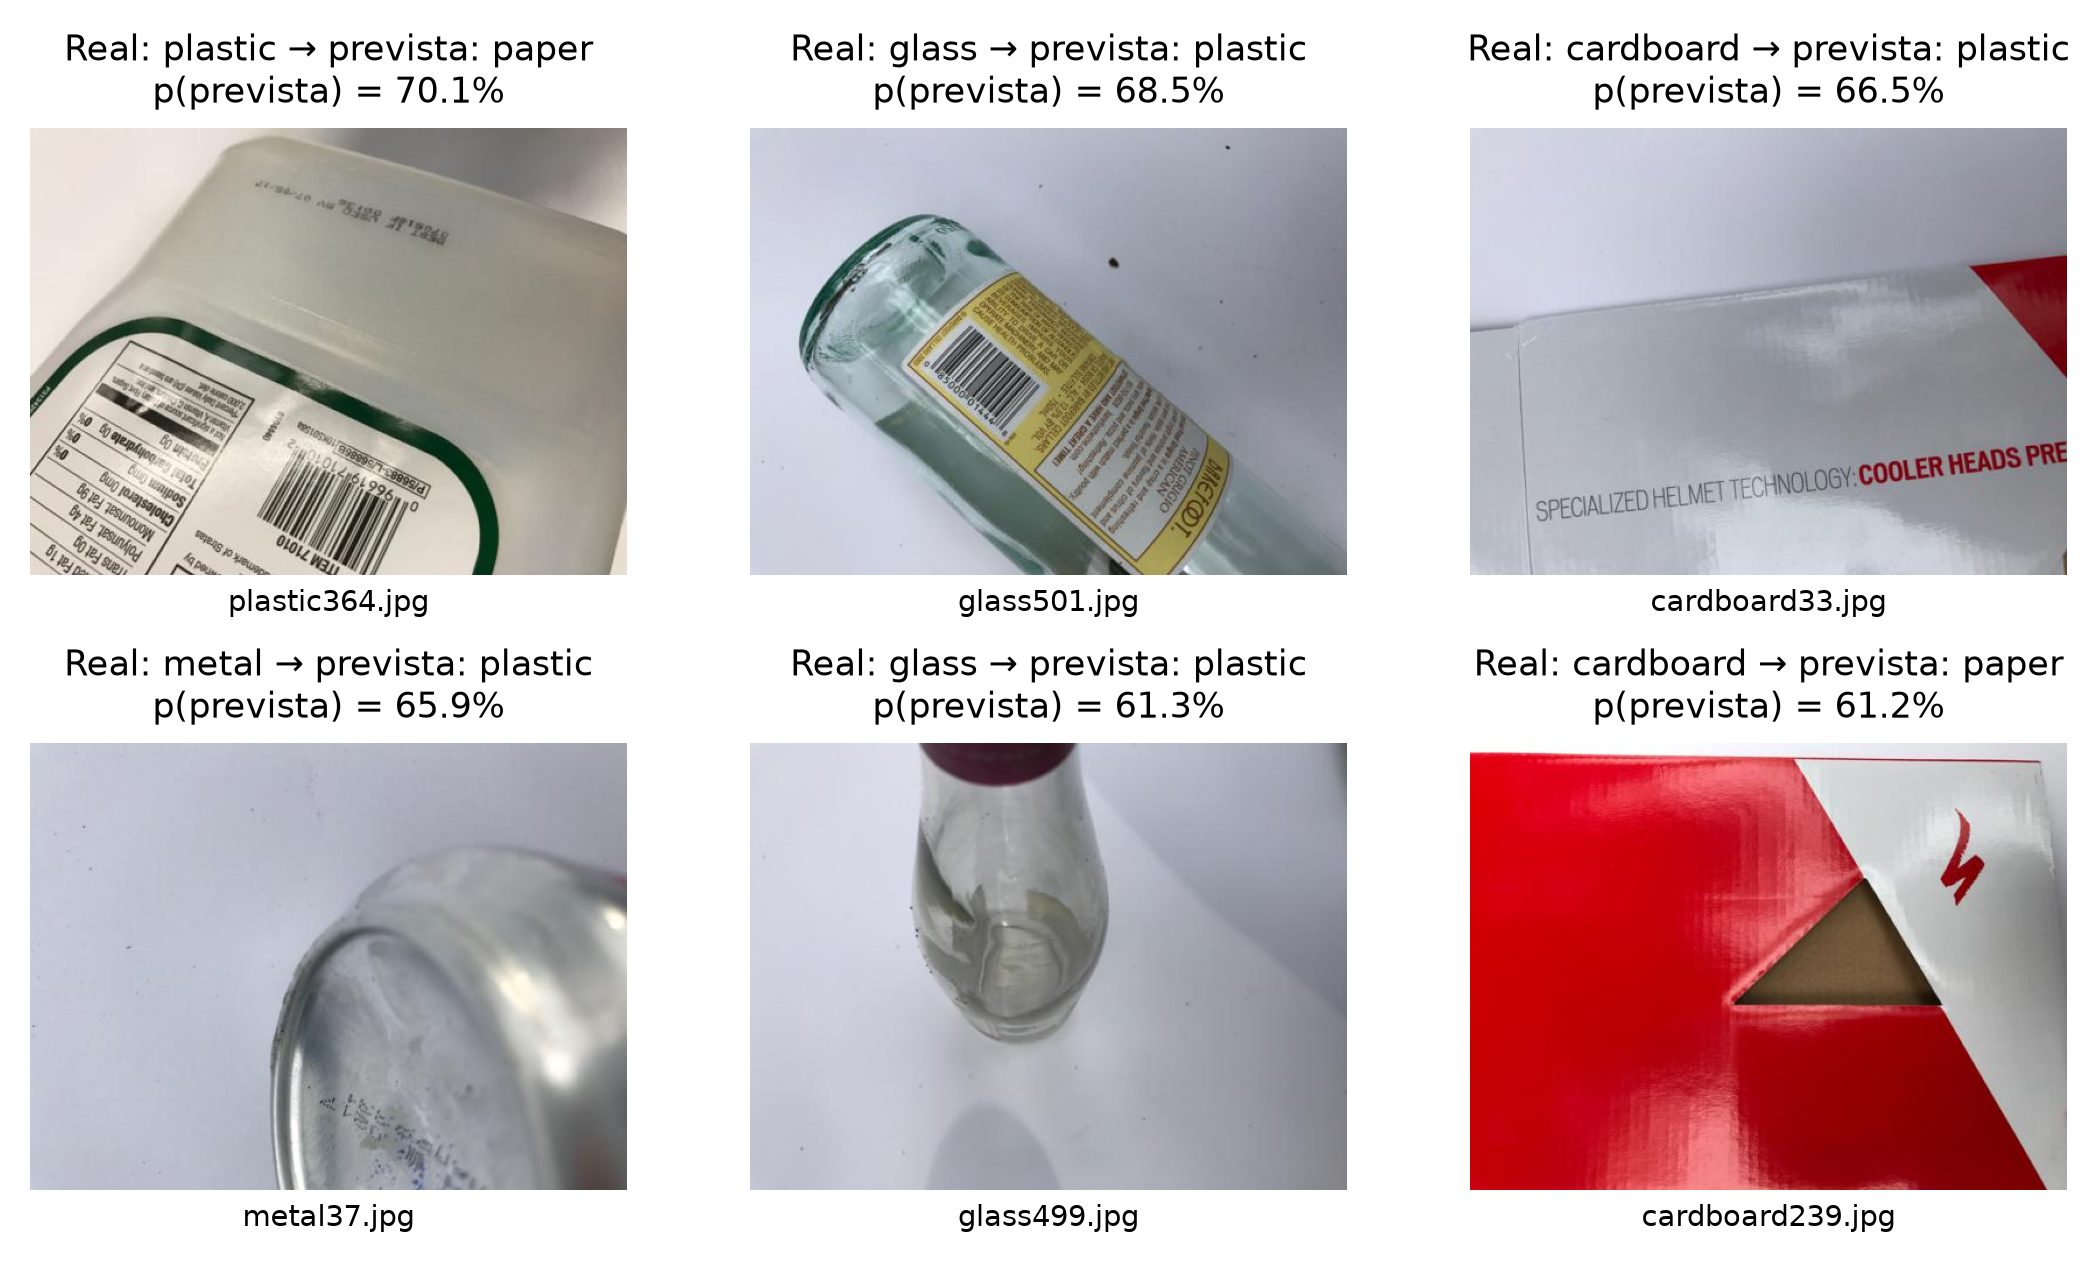

In [16]:
selected = lock['selected_experiment']
chosen_predictions = predictions[selected]
mistakes = chosen_predictions.loc[chosen_predictions.y_true != chosen_predictions.y_pred].sort_values(
    ['pred_probability','path'], ascending=[False,True])
error_record = vis.errors(ROOT, lock, FIGURES)
assert error_record['experiment'] == selected
assert error_record['total_test_errors'] == len(mistakes)
assert len(error_record['shown']) == min(6,len(mistakes))
print('Modelo:', vis.DISPLAY[selected])
print(f'Erros no teste: {len(mistakes)} de {len(chosen_predictions)} imagens.')
display(mistakes[['path','true_class','pred_class','pred_probability']].head(6).reset_index(drop=True))
display(DisplayImage(filename=str(FIGURES / 'fig08_analise_erros.png'), width=1100))

## Comparação com o estudo de referência e interpretação da equipe

Yang e Thung (2016) reportam **63% com SVM**, seis classes e divisão 70/30; a **CNN do
relatório alcança 22%**, usa cinco classes após excluir `trash`, entrada 256×256 e split
70/13/17. O README relata aproximadamente 75% em continuação posterior, e não como
resultado publicado naquele relatório. A comparação é contextual: classes, partições,
arquitetura e treinamento diferem. Fontes: [relatório original](https://cs229.stanford.edu/proj2016/report/ThungYang-ClassificationOfTrashForRecyclabilityStatus-report.pdf)
e [README oficial](https://github.com/garythung/trashnet).

A equipe deve relacionar os números acima com as imagens e as curvas: quais escolhas
ajudaram ou prejudicaram cada classe? A maior resolução compensou o custo? Quais erros
têm interpretação visual plausível? Quais conclusões não são suportadas por uma única
divisão? Registrem a revisão real em `GUIA_DA_EQUIPE.md`, sem declarar ações não realizadas.

## Interpretação dos resultados medidos

### Comparação das arquiteturas e pesos de classe

Em 128 × 96, a diferença CNN menos MLP no F1 macro de teste foi 0,1658 sem pesos e 0,2414 com pesos. Essas diferenças descrevem as arquiteturas e o orçamento adotados, sem estabelecer superioridade universal.

Na CNN, ponderar elevou o recall de trash de 0 para 70% (14/20), mas sua precisão foi 28,57%: 35 das 49 previsões trash eram de outras classes. O recall de paper caiu de 84,27% para 50,56%; a acurácia global caiu 3,68 pontos percentuais, enquanto F1 macro subiu 4,77 pontos. Na MLP, trash passou a ter 11 acertos, mas glass ficou sem acertos e o F1 macro caiu 2,79 pontos. O benefício depende da arquitetura e da classe.

### Leitura das curvas

A linha vertical indica a época restaurada por menor perda de validação. O término da curva pode ocorrer depois dela, pois a paciência aguarda cinco épocas sem melhora. As métricas de treino foram agregadas durante atualizações, com dropout ativo na MLP; as de validação usam modo de avaliação. Portanto, validação acima de treino em alguns pontos não é, isoladamente, sinal de vazamento.

As MLPs completaram 25 épocas e salvaram a última: a perda de validação caiu de 1,714 para 1,375 sem pesos e de 1,758 para 1,478 com pesos. A redução até o limite não demonstra convergência nem sobreajuste persistente. Nas CNNs 128, ambas salvaram a época 17 e pararam na 22: o treino continuou melhorando sem nova mínima de validação. Na CNN ponderada, a acurácia de validação cresceu de 56,46% para 59,89% nesse intervalo, mas a perda piorou de 1,100 para 1,141. A divergência entre critérios ilustra por que recuperar a menor perda pode não recuperar a maior acurácia. As CNNs 256 e 512 completaram 25 épocas e restauraram, respectivamente, as épocas 23 e 24.

### Resolução e custo

Em 512 × 384 houve apenas um acerto adicional em 380 imagens: 236 contra 235 em 128 × 96. O F1 macro caiu de 0,5241 para 0,5223; 256 × 192 também não melhorou o teste. Com 16 vezes mais pixels e os mesmos 24.086 parâmetros, 512 × 384 custou 22,52 vezes mais por época, 25,59 vezes no total e 3,98 vezes em RSS. Neste protocolo, 128 × 96 ofereceu a melhor relação entre F1 e custo entre as CNNs sem pesos; aumentar a resolução não compensou.

### Inspeção visual dos erros

O modelo selecionado errou 159 das 380 imagens de teste. O painel mostra até seis erros com maior probabilidade atribuída à classe prevista, com desempate pelo caminho do arquivo. Esse critério expõe erros de alta probabilidade, não uma amostra representativa de todos os erros. Softmax não equivale a confiança calibrada.

Em plastic364, o grande rótulo impresso ocupa parte da embalagem prevista como papel. Glass501 e glass499 são garrafas transparentes previstas como plástico. Cardboard33 apresenta superfície lisa e brilhante; metal37 mostra apenas parte de uma superfície curva refletiva: ambos foram previstos como plástico. Cardboard239, previsto como papel, exibe impressão colorida sobre a caixa. São hipóteses visuais de ambiguidade, sem prova de quais atributos a rede utilizou.

Na matriz de M4, paper → plastic e metal → glass somam 15 erros cada; glass → metal e glass → trash têm 14 cada. O painel de alta probabilidade não reproduz necessariamente essa frequência. Ruído nos rótulos de treino e semelhança entre embalagens limitam a interpretação, mesmo sem cópias exatas atravessando as partições.

Os códigos M1–M6 seguem a ordem dos seis experimentos no README. A equipe deve conferir estas interpretações e registrar sua revisão efetiva antes da entrega.

In [17]:
required_figures = [
    'fig01_distribuicao','fig02_exemplos','fig03_resolucoes','fig04_curvas_aprendizagem',
    'fig05_matrizes_confusao','fig06_resolucao_desempenho','fig07_resolucao_custo','fig08_analise_erros']
assert all((FIGURES / f'{stem}.png').is_file() for stem in required_figures)
assert len(recomputed) == 6 and len(per_class) == 36
assert len(histories.experiment.unique()) == 6
print('Auditoria concluída: seis modelos, 36 linhas por classe e oito figuras presentes.')
print('Nenhum modelo foi treinado e nenhuma nova inferência de teste foi executada neste notebook.')

Auditoria concluída: seis modelos, 36 linhas por classe e oito figuras presentes.
Nenhum modelo foi treinado e nenhuma nova inferência de teste foi executada neste notebook.
